In [ ]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 29.6 MB/s eta 0:00:00


In [ ]:
import faiss
import numpy as np
from sentence_transformers import SentenceTransformer

In [ ]:
model = SentenceTransformer('all-MiniLM-L6-v2')
model

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SentenceTransformer(
  (0): Transformer({'max_seq_length': 256, 'do_lower_case': False, 'architecture': 'BertModel'})
  (1): Pooling({'word_embedding_dimension': 384, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
  (2): Normalize()
)

In [ ]:
documents = ['The cat on the mat',
             'Dog is mans good freind',
             'The quick brown fox jumps over the lazy dog',
             'I love playing football every weekend',
             'Rugby is a game which is another football played is USA']
documents

['The cat on the mat',
 'Dog is mans good freind',
 'The quick brown fox jumps over the lazy dog',
 'I love playing football every weekend',
 'Rugby is a game which is another football played is USA']

In [ ]:
embedding = model.encode(documents,show_progress_bar=True)
print(embedding)
print(len(embedding[0]))

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

[[ 0.09828969  0.02133658 -0.02071243 ...  0.01456775  0.02543853
   0.06863783]
 [-0.05827083 -0.07393187  0.05586511 ...  0.08470144  0.05339587
   0.03155359]
 [ 0.03549681  0.06128627  0.05269207 ...  0.05468309  0.05382336
   0.08676742]
 [ 0.00416544 -0.05110837  0.02057047 ...  0.00714683 -0.00811263
  -0.05875875]
 [ 0.0190391   0.0029417  -0.05290598 ... -0.04158395  0.09234682
   0.00769587]]
384


In [ ]:
embedding.dtype

dtype('float32')

In [ ]:
dimension = embedding.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(embedding)
print("No I have created-", index.ntotal)

No I have created- 5


In [ ]:
query = 'Tell me a story'
query_vec = model.encode([query])
query_vec
print(query_vec.dtype)
print(len(query_vec))

float32
1


In [ ]:
k = 1
distances, indices = index.search(query_vec, k)
print(distances)
print(indices)

[[1.6600944]]
[[1]]


In [ ]:
for i in search_indices[0]:
  print(documents[i])

Dog is mans good freind


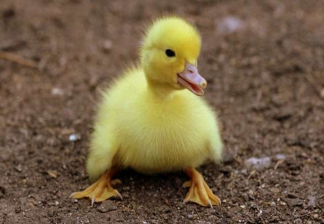

In [ ]:
from PIL import Image
image = Image.open('/content/baby-duck.jpeg')
image = image.resize((324,224))
image

In [ ]:
model2 = SentenceTransformer('clip-vit-B-32')
model2

modules.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: /root/.cache/huggingface/hub/models--sentence-transformers--clip-vit-B-32/snapshots/327ab6726d33c0e22f920c83f2ff9e4bd38ca37f/0_CLIPModel
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


SentenceTransformer(
  (0): CLIPModel()
)

In [ ]:
embd = model2.encode(image)
embd.shape

(512,)

In [ ]:
embd

array([ 4.51984942e-01, -8.14857781e-02,  2.02988058e-01, -5.65463901e-02,
       -5.68836033e-02, -7.92132616e-01,  3.14120263e-01,  3.20402324e-01,
       -2.61126071e-01,  8.36765766e-02, -2.80264392e-02, -2.57558167e-01,
       -3.34049344e-01, -2.95725822e-01,  7.48119593e-01, -9.81357992e-02,
        4.57479924e-01, -2.19461605e-01,  1.12439081e-01, -9.57553089e-02,
       -7.11639643e-01,  1.50777623e-02,  1.52564853e-01, -1.84578508e-01,
       -6.64989293e-01, -2.45296031e-01,  1.81996465e-01, -4.08839524e-01,
        1.03834420e-01, -4.12784070e-02,  6.66339815e-01,  3.11211377e-01,
       -3.27218354e-01,  5.35081983e-01,  5.64049423e-01,  1.76383615e-01,
       -2.28769183e-02,  2.56652385e-01,  1.58653677e-01,  9.99946237e-01,
       -2.36111149e-01, -1.11710846e-01,  3.00953567e-01, -9.35975239e-02,
        2.02385351e-01,  1.39642084e+00,  2.39335477e-01, -1.82936326e-01,
        1.22136727e-01,  2.60944694e-01, -3.33324552e-01,  1.79164290e-01,
        2.06813365e-02, -

In [ ]:
text_embd = model2.encode("A photo of baby duck")
text_embd

array([ 2.48063207e-02,  1.47114277e-01,  1.66382790e-01,  1.80819124e-01,
        1.70720667e-01, -2.47366026e-01, -1.03003778e-01, -7.60688424e-01,
       -6.26306057e-01, -1.96143031e-01, -2.50759661e-01, -3.56753379e-01,
       -2.31817350e-01, -1.24275967e-01,  4.47565466e-01,  7.82650262e-02,
        1.08128473e-01,  1.40754655e-01, -4.82494757e-02,  1.34822831e-01,
        2.45586604e-01,  9.95618850e-03,  4.61880267e-01,  2.91184455e-01,
       -4.43895310e-01, -3.95694748e-03,  1.04624480e-01,  1.97820425e-01,
       -1.83151111e-01, -3.48251462e-02,  3.06593478e-01,  3.68211567e-01,
        1.37697160e-03,  3.68739337e-01, -1.61110938e-01, -5.75315803e-02,
        2.42970034e-01, -1.69562638e-01,  1.17468528e-01,  3.44269067e-01,
       -2.71403044e-01,  1.99387833e-01, -1.62482798e-01,  1.03777289e-01,
        4.77713436e-01,  1.50539190e-01,  4.16244239e-01, -1.32174373e-01,
       -1.40810609e-02,  2.65697211e-01,  1.88661098e-01, -2.88761854e-01,
       -1.20154694e-01, -

In [ ]:
faiss.write_index(faiss_index,'faiss_text_index.index')

In [ ]:
load_index = faiss.read_index('faiss_text_index.index')
print(load_index)

<faiss.swigfaiss_avx2.IndexFlatL2; proxy of <Swig Object of type 'faiss::IndexFlatL2 *' at 0x7ab6499fc900> >


In [ ]:
query = "The poor animal are taken by the police in delhi"
query_vec = model.encode([query])
k = 1
distance, indices = load_index.search(query_vec,k)
print(distance)
print(indices)

[[1.2814023]]
[[2]]


In [ ]:
for i in indices[0]:
  print(documents[i])

The quick brown fox jumps over the lazy dog


In [ ]:
from re import search

In [ ]:
!pip install chromadb

In [ ]:
import chromadb
from chromadb.config import Settings

In [ ]:
client = chromadb.Client()

In [ ]:
collection = client.get_or_create_collection(name = 'documents')
collection

Collection(name=documents)

In [ ]:
collection.add(documents = documents,
               ids = [str(i) for i in range(len(documents))],embedding = embedding.tolist())

NameError: name 'documents' is not defined